# Trabajo Práctico — Análisis Estadístico II (602)

**Universidad de Buenos Aires — Facultad de Ciencias Económicas**  
**Año académico: 2025**  
**Autoría:** Ayelen Lang  
**Tema:** Comparación del crecimiento real del PIB per cápita en Dinamarca, Noruega y Finlandia  
**Fecha de referencia estadística:** junio de 2025

## Introducción y objetivo

El presente trabajo analiza las tasas de crecimiento real anual del producto interno bruto (PIB) per cápita de tres economías nórdicas: **Dinamarca, Noruega y Finlandia**. El objetivo es caracterizar su comportamiento histórico y evaluar, mediante herramientas de estadística inferencial, si existen diferencias en sus tasas de crecimiento y en la proporción de años con crecimiento positivo.

Se desarrollan estimaciones puntuales e intervalos de confianza, contrastes de hipótesis, análisis de varianza, una prueba de bondad de ajuste y un modelo de regresión lineal simple. Se adopta un **nivel de significación del 5 %** y, en los intervalos de confianza, un **nivel de confianza del 95 %**.

El trabajo utiliza la base **World Development Indicators** (Banco Mundial), edición del **5 de junio de 2025**. El último año de referencia considerado es 2024, dado que en junio de 2025 no se disponía de una observación anual completa correspondiente a ese año.


In [1]:
"""Análisis Estadístico II (602), FCE-UBA. Indicadores del Banco Mundial, junio de 2025."""

from __future__ import annotations

import hashlib
import itertools
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.stats.multitest import multipletests

COURSE = "Análisis Estadístico II (602) · Facultad de Ciencias Económicas · UBA"
CUTOFF = "2025-06-05"
ARCHIVE_VERSION = "202506"
START_YEAR = 1961
END_YEAR = 2024
ALPHA = 0.05
HAC_LAGS = 3
RNG_SEED = 6022025
COUNTRIES = {"DNK": "Dinamarca", "NOR": "Noruega", "FIN": "Finlandia"}
INDICATORS = {
    "NY.GDP.PCAP.KD.ZG": "crecimiento_real",  # % anual, variable principal
    "NY.GDP.PCAP.CD": "pib_nominal",           # USD corrientes, contextual
}
ARCHIVE_URL = "https://datatopics.worldbank.org/world-development-indicators/wdi-archives.html"
API_BASE = "https://api.worldbank.org/v2/sources/57"
OUT = Path.cwd() / "resultados_2025"
CSV = OUT / "datos_bm_archivo_junio_2025.csv"
META = OUT / "metadatos.json"




## Datos, variables y metodología

**Fuente:** Banco Mundial, *World Development Indicators (WDI)*, publicación del 5 de junio de 2025. La información se extrae de la edición histórica identificada como `202506`.

**Unidad de observación:** país y año. Se estudia el período **1961–2024**, sujeto a disponibilidad del indicador. Para las comparaciones se consideran solamente años con observaciones disponibles en los tres países; no se interpolan valores faltantes.

**Variable principal:** crecimiento real anual del PIB per cápita (%), indicador `NY.GDP.PCAP.KD.ZG`. Cada país constituye una serie de la misma variable, expresada en unidades comparables. También se presenta el PIB per cápita en dólares corrientes (`NY.GDP.PCAP.CD`) como referencia descriptiva, sin utilizar sus niveles nominales para los contrastes.

**Criterio inferencial:** al tratarse de observaciones anuales emparejadas por país y potencialmente autocorrelacionadas, se emplean diferencias por año y errores estándar HAC (*heteroskedasticity and autocorrelation consistent*) para las comparaciones de medias y proporciones. Se indican expresamente los supuestos adicionales exigidos por cada procedimiento.


In [2]:
def archive_url(code: str, indicator: str) -> str:
    return (f"{API_BASE}/country/{code}/series/{indicator}/time/all/"
            f"version/{ARCHIVE_VERSION}/data?format=json&per_page=1000")


def fetch_archived_data() -> pd.DataFrame:
    """Accede al origen versionado (source=57); nunca a la WDI actual."""
    rows: list[dict] = []
    session = requests.Session()
    for code, name in COUNTRIES.items():
        for indicator, variable in INDICATORS.items():
            url = archive_url(code, indicator)
            try:
                res = session.get(url, timeout=40, headers={"User-Agent": "UBA-TP-Analisis-II-2025/1.0"})
                res.raise_for_status()
                payload = res.json()
            except (requests.RequestException, ValueError) as exc:
                raise RuntimeError(
                    f"No se pudo consultar el archivo histórico 202506: {url}\n"
                    "Verificá la conexión o ejecutá con un CSV previamente guardado."
                ) from exc
            if "source" not in payload:
                raise RuntimeError(f"La respuesta de WDI Archive no contiene 'source': {str(payload)[:350]}")
            source = payload["source"]
            if isinstance(source, dict) and str(source.get("id")) != "57":
                raise RuntimeError(f"Origen inesperado, se exige source 57: {source.get('id')}")
            entries = source.get("data", []) if isinstance(source, dict) else []
            if not isinstance(entries, list):
                raise RuntimeError(f"Formato inesperado del archivo WDI: {url}")
            pages = int(payload.get("pages", 1))
            if pages > 1:
                raise RuntimeError("La API devolvió más páginas de las previstas; subí per_page.")
            count = 0
            for rec in entries:
                dims = {dim["concept"].lower(): dim["id"] for dim in rec.get("variable", [])}
                yr_str = dims.get("time", "").upper().replace("YR", "")
                if not yr_str.isdigit():
                    continue
                year = int(yr_str)
                value = rec.get("value")
                if not (START_YEAR <= year <= END_YEAR) or value is None:
                    continue
                if dims.get("version") != ARCHIVE_VERSION:
                    raise ValueError(f"Versión inesperada: {dims.get('version')}, no {ARCHIVE_VERSION}")
                if dims.get("series", "").upper() != indicator.upper():
                    raise ValueError(f"Serie inesperada: {dims.get('series')}")
                rows.append({"anio": year, "pais": name, "serie": variable, "valor": float(value)})
                count += 1
            if count < 50:
                raise RuntimeError(
                    f"Menos de 50 observaciones archivadas para {name}/{variable} ({count}). "
                    "Revisá la versión 202506 y la disponibilidad de esta serie."
                )
    return pd.DataFrame(rows)


def data_table(force_download: bool = False) -> pd.DataFrame:
    OUT.mkdir(parents=True, exist_ok=True)
    if force_download or not CSV.exists():
        raw = fetch_archived_data()
        raw.sort_values(["serie", "pais", "anio"]).to_csv(CSV, index=False, float_format="%.12g")
        metadata = {
            "materia": COURSE, "edicion": "2025",
            "fecha_archivo_world_bank": CUTOFF, "version_archivo": ARCHIVE_VERSION,
            "fuente": "World Development Indicators, edición del 5 de junio de 2025",
            "url_catalogo": ARCHIVE_URL,
            "fecha_maxima_dato": END_YEAR,
            "indicadores": INDICATORS,
            "paises": COUNTRIES,
            "sha256_csv": hashlib.sha256(CSV.read_bytes()).hexdigest(),
        }
        META.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    # Verificación de procedencia y consistencia de los datos.
    if not META.exists():
        raise RuntimeError("Falta metadatos.json: no es posible verificar el origen archivado del CSV. "
                           "Se requiere obtener nuevamente los archivos de datos.")
    provenance = json.loads(META.read_text(encoding="utf-8"))
    if (provenance.get("version_archivo") != ARCHIVE_VERSION or
            provenance.get("fecha_archivo_world_bank") != CUTOFF or
            provenance.get("sha256_csv") != hashlib.sha256(CSV.read_bytes()).hexdigest()):
        raise RuntimeError("No se puede validar la versión y hash del CSV. "
                           "Se requiere recuperar nuevamente la base histórica.")
    data = pd.read_csv(CSV)
    required = {"anio", "pais", "serie", "valor"}
    if not required.issubset(data):
        raise ValueError(f"Columnas requeridas del CSV: {required}")
    if not ((data["anio"].between(START_YEAR, END_YEAR)).all()):
        raise ValueError("Los datos incluyen años fuera del horizonte declarado.")
    if data.duplicated(["anio", "pais", "serie"]).any():
        raise ValueError("La tabla tiene observaciones duplicadas país-año-serie.")
    return data


def matrices(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    def pivot(series: str) -> pd.DataFrame:
        x = (raw.query("serie == @series")
             .pivot(index="anio", columns="pais", values="valor")
             .reindex(columns=list(COUNTRIES.values()))
             .sort_index())
        # Comparación país-año: emparejamiento explícito; no completar artificialmente.
        return x.dropna()
    growth, levels = pivot("crecimiento_real"), pivot("pib_nominal")
    if len(growth) < 50:
        raise ValueError(f"Se requieren 50 años completos como mínimo. Hay {len(growth)}.")
    print(f"Muestra principal: {len(growth)} años compartidos, {growth.index.min()}–{growth.index.max()}.")
    print(f"Datos contextuales: {len(levels)} años compartidos, {levels.index.min()}–{levels.index.max()}.")
    return growth, levels


In [3]:
raw = data_table()
growth, levels = matrices(raw)
print('Cinco primeros años:')
display(growth.head())
print('Últimos años observados:')
display(growth.tail())
print('Ausencias luego de emparejar:')
print(growth.isna().sum().to_string())
assert len(growth) >= 50
assert growth.index.max() <= 2024

Muestra principal: 63 años compartidos, 1961–2023.
Datos contextuales: 63 años compartidos, 1961–2023.
Cinco primeros años:


pais,Dinamarca,Noruega,Finlandia
anio,,,
1961,5.638744,5.432493,6.847965
1962,4.847447,1.991246,2.284049
1963,-0.152610,3.003259,2.557472
1964,8.400119,4.219394,4.654853
1965,3.743685,4.470368,4.952389


Últimos años observados:


pais,Dinamarca,Noruega,Finlandia
anio,,,
2019,1.347792,0.443429,1.238121
2020,-2.066138,-1.857696,-2.630999
2021,6.917664,3.354495,2.521977
2022,0.743682,2.084382,1.174535
2023,1.738313,-0.657513,-1.656115


Ausencias luego de emparejar:
pais
Dinamarca    0
Noruega      0
Finlandia    0


## 1. Estimación puntual de parámetros

Para cada serie se estiman la media, las varianzas y los desvíos estándar con divisor $n$ (sesgados) y divisor $n-1$ (insesgados). Se define, además, la proporción $\hat p$ de años con crecimiento real del PIB per cápita positivo.

$$
\bar x=\frac{1}{n}\sum_{i=1}^{n}x_i,\qquad
s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar x)^2,\qquad
\hat p=\frac{\#\{x_i>0\}}{n}.
$$

Las tablas de frecuencias agrupan las observaciones en intervalos definidos mediante la regla de Sturges. La media del crecimiento se expresa en puntos porcentuales anuales.


In [4]:
def hac_mean(y, lags: int = HAC_LAGS) -> tuple[float, float, tuple[float, float], float]:
    """Estimación de media + IC 95% robusto HAC, aproximación asintótica."""
    arr = np.asarray(y, dtype=float)
    fit = sm.OLS(arr, np.ones((len(arr), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": min(lags, len(arr) - 1)})
    val = float(fit.params[0]); se = float(fit.bse[0])
    z = stats.norm.ppf(1 - ALPHA / 2)
    lo, hi = val - z * se, val + z * se
    p = float(2 * stats.norm.sf(abs(val / se))) if se > 0 else (0.0 if val else 1.0)
    return val, se, (lo, hi), p


def circular_block_bootstrap(y, stat_fun=np.var, reps: int = 2000,
                             block: int = 4, seed: int = RNG_SEED) -> tuple[float, float]:
    """Percentiles de bootstrap por bloques: incertidumbre con dependencia corta."""
    x = np.asarray(y, dtype=float)
    n = len(x)
    rng = np.random.default_rng(seed)
    values = np.empty(reps)
    for b in range(reps):
        starts = rng.integers(0, n, size=int(np.ceil(n / block)))
        indices = np.concatenate([(s + np.arange(block)) % n for s in starts])[:n]
        values[b] = stat_fun(x[indices])
    return tuple(float(v) for v in np.quantile(values, [0.025, 0.975]))


def descriptions_and_intervals(g: pd.DataFrame) -> pd.DataFrame:
    """Sección 1–2: medias, varianzas, desvíos, proporciones e intervalos."""
    rows = []
    for c in g:
        x = g[c].to_numpy()
        n = len(x)
        m, se, (lomu, himu), _ = hac_mean(x)
        s2 = float(np.var(x, ddof=1))
        # Fórmula chi² clásica SOLO bajo normalidad iid, declarada como referencia.
        lvar_iid = (n - 1) * s2 / stats.chi2.ppf(0.975, n - 1)
        hvar_iid = (n - 1) * s2 / stats.chi2.ppf(0.025, n - 1)
        lvar_block, hvar_block = circular_block_bootstrap(
            x, stat_fun=lambda z: np.var(z, ddof=1), seed=RNG_SEED + len(c))
        event = (x > 0).astype(float)
        p, sep, (lop, hip), _ = hac_mean(event)
        rows.append({
            "País": c, "n": n, "Media (pp)": m,
            "Var. sesgada": float(np.var(x, ddof=0)),
            "Var. insesgada": s2,
            "Desv. sesgado": float(np.std(x, ddof=0)),
            "Desv. muestral": float(np.std(x, ddof=1)),
            "Prop. crecimiento > 0": p,
            "IC media HAC inf": lomu, "IC media HAC sup": himu,
            "IC var. χ² iid inf": lvar_iid, "IC var. χ² iid sup": hvar_iid,
            "IC var. bloques inf": lvar_block, "IC var. bloques sup": hvar_block,
            "IC prop. HAC inf": max(0.0, lop), "IC prop. HAC sup": min(1.0, hip),
            "EE(media) HAC": se, "EE(prop) HAC": sep,
        })
    return pd.DataFrame(rows).set_index("País")


def frequency_tables(g: pd.DataFrame) -> dict[str, pd.DataFrame]:
    freq = {}
    for col in g:
        cnt, edges = np.histogram(g[col], bins="sturges")
        df = pd.DataFrame({"límite_inf": edges[:-1], "límite_sup": edges[1:],
                           "frecuencia": cnt, "fracción": cnt / cnt.sum()})
        assert int(df["frecuencia"].sum()) == len(g)
        freq[col] = df
    return freq


In [5]:
descriptive = descriptions_and_intervals(growth)
freq = frequency_tables(growth)
for pais, tabla in freq.items():
    print(f'\nFrecuencias — {pais} (suma={tabla.frecuencia.sum()})')
    display(tabla.round(4))
print('Estimaciones puntuales:')
display(descriptive[['n','Media (pp)','Var. sesgada','Var. insesgada',
                     'Desv. sesgado','Desv. muestral','Prop. crecimiento > 0']].round(4))


Frecuencias — Dinamarca (suma=63)


,límite_inf,límite_sup,frecuencia,fracción
0,-5.4816,-3.4985,1,0.0159
1,-3.4985,-1.5154,2,0.0317
2,-1.5154,0.4677,11,0.1746
3,0.4677,2.4508,24,0.3810
4,2.4508,4.4339,15,0.2381
5,4.4339,6.4170,8,0.1270
6,6.4170,8.4001,2,0.0317



Frecuencias — Noruega (suma=63)


,límite_inf,límite_sup,frecuencia,fracción
0,-3.1693,-1.8946,1,0.0159
1,-1.8946,-0.6199,4,0.0635
2,-0.6199,0.6548,9,0.1429
3,0.6548,1.9295,14,0.2222
4,1.9295,3.2042,10,0.1587
5,3.2042,4.4788,16,0.2540
6,4.4788,5.7535,9,0.1429



Frecuencias — Finlandia (suma=63)


,límite_inf,límite_sup,frecuencia,fracción
0,-8.5146,-5.9187,2,0.0317
1,-5.9187,-3.3227,1,0.0159
2,-3.3227,-0.7268,6,0.0952
3,-0.7268,1.8691,14,0.2222
4,1.8691,4.4650,25,0.3968
5,4.4650,7.0610,12,0.1905
6,7.0610,9.6569,3,0.0476


Estimaciones puntuales:


,n,Media (pp),Var. sesgada,Var. insesgada,Desv. sesgado,Desv. muestral,Prop. crecimiento > 0
País,,,,,,,
Dinamarca,63,2.0352,5.5954,5.6856,2.3655,2.3845,0.8413
Noruega,63,2.2874,3.9275,3.9909,1.9818,1.9977,0.8571
Finlandia,63,2.3082,9.7069,9.8635,3.1156,3.1406,0.8413


## 2. Intervalos de confianza al 95 %

**Media y proporción:** se construyen intervalos basados en errores estándar HAC con tres rezagos y una aproximación normal asintótica. Los intervalos de proporciones se restringen al rango $[0,1]$.

**Varianza:** se presenta el intervalo clásico basado en la distribución $\chi^2$, cuya validez depende de normalidad e independencia, junto con un intervalo de percentiles obtenido mediante *bootstrap* circular por bloques de cuatro años, apropiado como aproximación bajo dependencia temporal de corto alcance y estabilidad de la serie.

Las comparaciones de intervalos individuales se complementan en el apartado siguiente con intervalos de diferencias entre países.


In [6]:
print('Intervalos individuales:')
display(descriptive[['IC media HAC inf','IC media HAC sup',
                     'IC var. χ² iid inf','IC var. χ² iid sup',
                     'IC var. bloques inf','IC var. bloques sup',
                     'IC prop. HAC inf','IC prop. HAC sup']].round(4))

Intervalos individuales:


,IC media HAC inf,IC media HAC sup,IC var. χ² iid inf,IC var. χ² iid sup,IC var. bloques inf,IC var. bloques sup,IC prop. HAC inf,IC prop. HAC sup
País,,,,,,,,
Dinamarca,1.3603,2.7100,4.1155,8.3680,3.4574,8.1536,0.7500,0.9325
Noruega,1.5493,3.0255,2.8888,5.8737,2.6856,5.1991,0.7442,0.9701
Finlandia,1.2891,3.3272,7.1396,14.5168,5.2429,14.3816,0.7291,0.9534


## 3. Contrastes de hipótesis: diferencias de medias y proporciones

Se contrastan las tres combinaciones posibles de países, comparando observaciones del mismo año.

**Diferencia de medias:**

$$H_0:\mathbb{E}(X_A-X_B)=0,\qquad H_1:\mathbb{E}(X_A-X_B)\ne 0.$$

**Diferencia de proporciones:** se define $I(X>0)$ como el indicador de crecimiento positivo y se evalúa

$$H_0:P(X_A>0)-P(X_B>0)=0,\qquad H_1:P(X_A>0)-P(X_B>0)\ne0.$$

Para cada diferencia anual se estima su media y error estándar HAC, con intervalos bilaterales del 95 %. Se rechaza $H_0$ si el **p-valor ajustado por Holm** es menor que $0{,}05$; este ajuste controla la multiplicidad de las tres comparaciones dentro de cada familia de pruebas. El contraste exacto de McNemar se consigna únicamente como referencia clásica, bajo el supuesto adicional de independencia entre años.


In [7]:
def pairwise_tests(g: pd.DataFrame) -> pd.DataFrame:
    """Sección 2–3: IC y test en diferencias emparejadas por año, HAC."""
    results = []
    for a, b in itertools.combinations(g.columns, 2):
        x = g[a].to_numpy(); y = g[b].to_numpy()
        d = x - y
        diff, se, ci, pv = hac_mean(d)
        pdiff = (x > 0).astype(float) - (y > 0).astype(float)
        diffprop, se_p, ci_p, pv_p = hac_mean(pdiff)
        # McNemar exacto como diagnóstico suplementario (iid de años supuesto).
        b10 = int(((x > 0) & (y <= 0)).sum())
        b01 = int(((x <= 0) & (y > 0)).sum())
        p_mcnemar = float(stats.binomtest(min(b10, b01), b10 + b01, 0.5).pvalue) if (b10 + b01) else 1.0
        results.append({
            "Comparación": f"{a} − {b}", "Δ media (pp)": diff,
            "EE HAC media": se, "IC media inf": ci[0], "IC media sup": ci[1],
            "p media HAC": pv, "Δ proporción": diffprop,
            "EE HAC prop.": se_p, "IC prop. inf": ci_p[0], "IC prop. sup": ci_p[1],
            "p prop. HAC": pv_p, "p McNemar (referencia iid)": p_mcnemar,
            "b10": b10, "b01": b01,
        })
    tbl = pd.DataFrame(results).set_index("Comparación")
    for nm in ["media", "prop."]:
        key = "p media HAC" if nm == "media" else "p prop. HAC"
        tbl[f"p {nm} Holm"] = multipletests(tbl[key].to_numpy(), method="holm")[1]
    return tbl


In [8]:
comparisons = pairwise_tests(growth)
display(comparisons.round(5))
for par, row in comparisons.iterrows():
    print(par)
    print('  Diferencia de medias:', 'Rechaza H₀' if row['p media Holm'] < .05 else 'No rechaza H₀',
          f"(p HAC={row['p media HAC']:.5f}, p ajustado Holm={row['p media Holm']:.5f})")
    print('  Diferencia de proporciones:', 'Rechaza H₀' if row['p prop. Holm'] < .05 else 'No rechaza H₀',
          f"(p HAC={row['p prop. HAC']:.5f}, p ajustado Holm={row['p prop. Holm']:.5f})")

,Δ media (pp),EE HAC media,IC media inf,IC media sup,p media HAC,Δ proporción,EE HAC prop.,IC prop. inf,IC prop. sup,p prop. HAC,p McNemar (referencia iid),b10,b01,p media Holm,p prop. Holm
Comparación,,,,,,,,,,,,,,,
Dinamarca − Noruega,-0.25221,0.27093,-0.78322,0.27880,0.35190,-0.01587,0.05588,-0.12540,0.09366,0.77639,1.0,6,7,1.0,1.0
Dinamarca − Finlandia,-0.27299,0.42334,-1.10271,0.55673,0.51902,0.00000,0.06349,-0.12444,0.12444,1.00000,1.0,6,6,1.0,1.0
Noruega − Finlandia,-0.02078,0.43760,-0.87846,0.83691,0.96213,0.01587,0.06236,-0.10635,0.13810,0.79908,1.0,6,5,1.0,1.0


Dinamarca − Noruega
  Diferencia de medias: No rechaza H₀ (p HAC=0.35190, p ajustado Holm=1.00000)
  Diferencia de proporciones: No rechaza H₀ (p HAC=0.77639, p ajustado Holm=1.00000)
Dinamarca − Finlandia
  Diferencia de medias: No rechaza H₀ (p HAC=0.51902, p ajustado Holm=1.00000)
  Diferencia de proporciones: No rechaza H₀ (p HAC=1.00000, p ajustado Holm=1.00000)
Noruega − Finlandia
  Diferencia de medias: No rechaza H₀ (p HAC=0.96213, p ajustado Holm=1.00000)
  Diferencia de proporciones: No rechaza H₀ (p HAC=0.79908, p ajustado Holm=1.00000)


## 4. Análisis de varianza (ANOVA)

Se considera el **país** como factor de análisis y el **año** como unidad de emparejamiento, dado que los valores de los tres países se registran durante los mismos períodos.

$$H_0:\mu_{DK}=\mu_{NO}=\mu_{FI}.$$

La hipótesis alternativa establece que **al menos una media es distinta**. Se aplica un ANOVA de medidas repetidas y se informa adicionalmente la prueba no paramétrica de Friedman.

El ANOVA requiere supuestos sobre la estructura de covarianzas de las mediciones y la independencia de los bloques anuales. La posible autocorrelación entre años se considera al interpretar sus resultados.


In [9]:
def repeated_measures_anova(g: pd.DataFrame):
    """Sección 4: ANOVA de medidas repetidas, bloqueo por año."""
    long = g.rename_axis("anio").reset_index().melt(
        id_vars="anio", var_name="pais", value_name="crecimiento")
    ans = AnovaRM(long, depvar="crecimiento", subject="anio", within=["pais"]).fit()
    friedman = stats.friedmanchisquare(*(g[c].to_numpy() for c in g))
    return ans, friedman


In [10]:
anova, friedman = repeated_measures_anova(growth)
print(anova)
print(f'Friedman χ²={friedman.statistic:.4f}; p={friedman.pvalue:.5g}')

               Anova
     F Value Num DF  Den DF  Pr > F
-----------------------------------
pais  0.4249 2.0000 124.0000 0.6548

Friedman χ²=2.5079; p=0.28537


## 5. Bondad de ajuste a una distribución normal

Se analiza si la distribución marginal del crecimiento anual del PIB per cápita de **Dinamarca** es compatible con una distribución normal:

$$H_0:X\sim N(\mu,\sigma^2),\qquad H_1:X\not\sim N(\mu,\sigma^2).$$

Se utiliza el estadístico de Kolmogorov–Smirnov. Como los parámetros $\mu$ y $\sigma$ se estiman con la misma muestra, el p-valor se obtiene mediante **bootstrap paramétrico** con 3.000 réplicas, estimando ambos parámetros nuevamente en cada réplica.

La distribución simulada corresponde a un esquema de observaciones independientes; por lo tanto, la interpretación inferencial requiere cautela ante autocorrelación temporal.


In [11]:
def normality_bootstrap(g: pd.DataFrame, country: str = "Dinamarca",
                        B: int = 3000) -> dict:
    """Sección 5: KS con parámetros estimados + p por bootstrap paramétrico.

    Es un contraste bajo iid; no valida independencia temporal.
    """
    x = g[country].to_numpy(dtype=float)
    n = len(x)
    m = x.mean(); sd = x.std(ddof=0)
    obs = float(stats.kstest(x, lambda value: stats.norm.cdf(value, loc=m, scale=sd)).statistic)
    rng = np.random.default_rng(RNG_SEED)
    sample_stats = np.empty(B)
    for j in range(B):
        simulated = rng.normal(m, sd, n)
        sim_mu = simulated.mean(); sim_sd = simulated.std(ddof=0)
        sample_stats[j] = stats.kstest(
            simulated, lambda value: stats.norm.cdf(value, loc=sim_mu, scale=sim_sd)
        ).statistic
    p = (1.0 + np.count_nonzero(sample_stats >= obs)) / (B + 1.0)
    return {"país": country, "n": n, "estadístico KS": obs, "p bootstrap": p,
            "réplicas": B, "media estimada": m, "desvío estimado": sd,
            "conclusión": "Rechaza normalidad" if p < ALPHA else "No rechaza normalidad"}


In [12]:
ks = normality_bootstrap(growth)
display(pd.Series(ks, name='Bondad de ajuste — Dinamarca').to_frame())

,Bondad de ajuste — Dinamarca
país,Dinamarca
n,63
estadístico KS,0.081173
p bootstrap,0.381206
réplicas,3000
media estimada,2.035165
desvío estimado,2.365454
conclusión,No rechaza normalidad


## 6. Modelo de regresión lineal simple

Se evalúa la asociación contemporánea entre el crecimiento real anual del PIB per cápita de Dinamarca y el de Noruega mediante el modelo:

$$g_{DK,t}=\beta_0+\beta_1g_{NO,t}+u_t.$$

La hipótesis individual es $H_0:\beta_1=0$ frente a $H_1:\beta_1\ne 0$. Para un modelo con un único regresor, la prueba global de significación corresponde al mismo contraste de pendiente. Se informan los estadísticos de significación con covarianza HAC, el coeficiente de determinación $R^2$ y los diagnósticos de Durbin–Watson y Breusch–Godfrey para los residuos.

La relación estimada se interpreta como **asociación estadística**, no como causalidad.


In [13]:
def regression(g: pd.DataFrame) -> tuple[object, dict]:
    """Sección 6: regresión simple de tasas reales con inferencia HAC."""
    X = sm.add_constant(g[["Noruega"]])
    y = g["Dinamarca"]
    ols = sm.OLS(y, X).fit()
    hac = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
    global_test = hac.f_test("Noruega = 0")  # 1 regresor => F robusto = t HAC²
    bg = acorr_breusch_godfrey(ols, nlags=3)
    diag = {"R²": float(ols.rsquared), "intercepto": float(hac.params["const"]),
            "pendiente": float(hac.params["Noruega"]),
            "p pendiente HAC": float(hac.pvalues["Noruega"]),
            "F global HAC": float(global_test.fvalue),
            "p global HAC": float(global_test.pvalue),
            "Durbin-Watson": float(sm.stats.stattools.durbin_watson(ols.resid)),
            "BG LM p (3 rezagos)": float(bg[1]),
            "n": len(g)}
    return hac, diag


In [14]:
fit, reg = regression(growth)
print(fit.summary())
print('Diagnósticos y contraste global:')
display(pd.Series(reg, name='Regresión de crecimiento real').to_frame())

                            OLS Regression Results                            
Dep. Variable:              Dinamarca   R-squared:                       0.347
Model:                            OLS   Adj. R-squared:                  0.336
Method:                 Least Squares   F-statistic:                     31.88
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           4.55e-07
Time:                        10:33:51   Log-Likelihood:                -130.22
No. Observations:                  63   AIC:                             264.4
Df Residuals:                      61   BIC:                             268.7
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4275      0.323      1.325      0.1

/tmp/ipykernel_3083718/4032904766.py:8: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg = acorr_breusch_godfrey(ols, nlags=3)


,Regresión de crecimiento real
R²,3.467223e-01
intercepto,4.275418e-01
pendiente,7.028237e-01
p pendiente HAC,1.636512e-08
F global HAC,3.188410e+01
p global HAC,4.546623e-07
Durbin-Watson,2.045907e+00
BG LM p (3 rezagos),7.342621e-01
n,6.300000e+01


## 7. Representación gráfica de los resultados

Se presentan la evolución temporal de las tres series de crecimiento real, los niveles de PIB per cápita nominal como contexto, la distribución empírica del crecimiento danés y la relación lineal estimada entre Dinamarca y Noruega.


In [15]:
def graficar_resultados(g: pd.DataFrame, nominal: pd.DataFrame, modelo) -> None:
    plt.rcParams.update({"figure.figsize": (9, 4.8), "font.size": 10, "axes.grid": True})

    fig, ax = plt.subplots()
    g.plot(ax=ax, linewidth=1.7)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title="Crecimiento real anual del PIB per cápita", xlabel="Año", ylabel="Variación anual (%)")
    fig.tight_layout()
    plt.show()

    if not nominal.empty:
        fig, ax = plt.subplots()
        nominal.plot(ax=ax, linewidth=1.7)
        ax.set(title="PIB per cápita nominal", xlabel="Año", ylabel="USD corrientes")
        fig.tight_layout()
        plt.show()

    x = g["Dinamarca"].to_numpy()
    fig, ax = plt.subplots()
    ax.hist(x, bins="sturges", density=True, alpha=0.7, edgecolor="white")
    eje_x = np.linspace(x.min(), x.max(), 220)
    ax.plot(eje_x, stats.norm.pdf(eje_x, loc=x.mean(), scale=x.std(ddof=0)), color="black", linewidth=2)
    ax.set(title="Dinamarca: distribución del crecimiento anual", xlabel="Variación anual (%)", ylabel="Densidad")
    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots()
    ax.scatter(g["Noruega"], g["Dinamarca"], alpha=0.75)
    eje_x = np.linspace(g["Noruega"].min(), g["Noruega"].max(), 100)
    ax.plot(eje_x, modelo.params["const"] + modelo.params["Noruega"] * eje_x, color="black", linewidth=2)
    ax.set(title="Regresión lineal: crecimiento real anual", xlabel="Noruega (puntos porcentuales)",
           ylabel="Dinamarca (puntos porcentuales)")
    fig.tight_layout()
    plt.show()


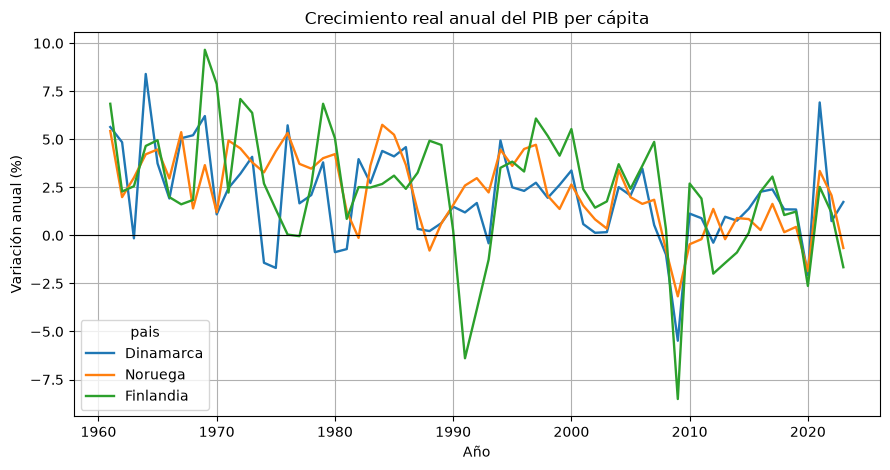

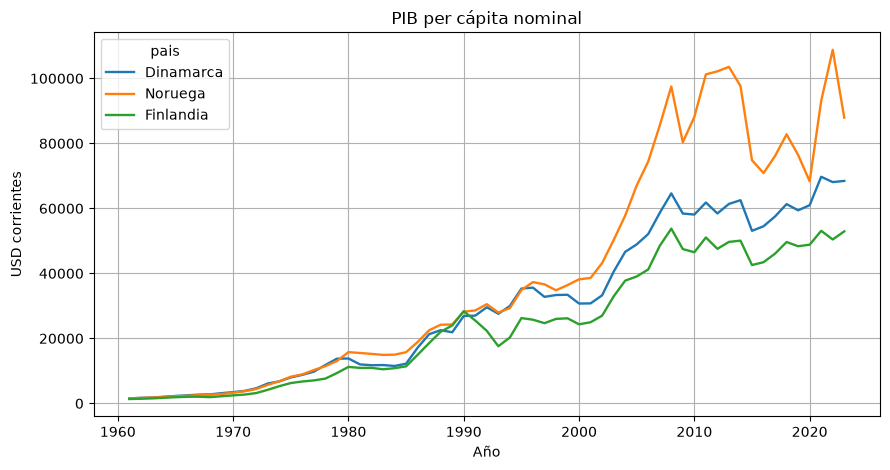

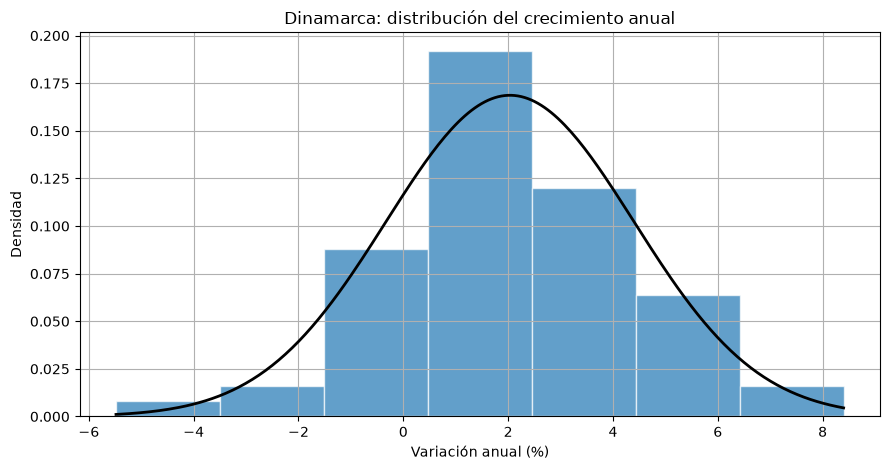

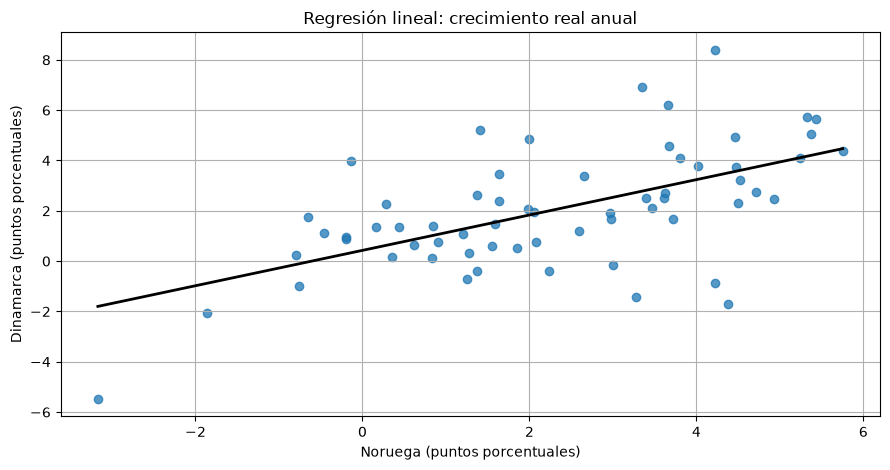

In [16]:
graficar_resultados(growth, levels, fit)


## 8. Conclusiones generales

El estudio permite comparar la evolución del crecimiento real anual del PIB per cápita entre Dinamarca, Noruega y Finlandia mediante estimaciones descriptivas, intervalos y contrastes de hipótesis. El uso de observaciones correspondientes a los mismos años favorece comparaciones emparejadas, y la estimación HAC incorpora una aproximación al efecto de la dependencia temporal de corto alcance.

La evidencia estadística debe interpretarse dentro del período analizado. Los países comparten condiciones internacionales, shocks macroeconómicos y períodos de expansión o contracción que pueden influir simultáneamente en sus series. Los resultados del ANOVA y de la prueba de normalidad dependen de sus propios supuestos, mientras que la regresión expresa una relación estadística contemporánea sin establecer causalidad.

A continuación se presentan las decisiones inferenciales y los principales indicadores calculados para la muestra.


In [17]:
from IPython.display import Markdown, display

medias = descriptive['Media (pp)']
orden = medias.sort_values(ascending=False)
lineas = [
    f"**Período efectivamente analizado:** {growth.index.min()}–{growth.index.max()} "
    f"({len(growth)} observaciones anuales por país).",
    f"**Estimación descriptiva:** {orden.index[0]} presenta la mayor tasa media de crecimiento anual "
    f"({orden.iloc[0]:.2f} %), seguido de {orden.index[1]} ({orden.iloc[1]:.2f} %) "
    f"y {orden.index[2]} ({orden.iloc[2]:.2f} %).",
]

comparaciones_sig = []
for paises, fila in comparisons.iterrows():
    if fila['p media Holm'] < ALPHA:
        comparaciones_sig.append(paises)
if comparaciones_sig:
    lineas.append("**Diferencias de medias:** se rechaza la igualdad de medias al 5 % "
                  "(ajuste de Holm) en: " + ", ".join(comparaciones_sig) + ".")
else:
    lineas.append("**Diferencias de medias:** no se rechaza la igualdad de medias "
                  "en ninguna comparación bilateral al 5 % después del ajuste de Holm.")

proporciones_sig = [par for par, fila in comparisons.iterrows() if fila['p prop. Holm'] < ALPHA]
if proporciones_sig:
    lineas.append("**Diferencias de proporciones:** se observan diferencias significativas "
                  "en la proporción de años de crecimiento positivo para: "
                  + ", ".join(proporciones_sig) + ".")
else:
    lineas.append("**Diferencias de proporciones:** no se detectan diferencias significativas "
                  "después del ajuste de Holm.")

p_anova = float(anova.anova_table['Pr > F'].iloc[0])
lineas.append(f"**ANOVA de medidas repetidas:** F = {float(anova.anova_table['F Value'].iloc[0]):.3f}; "
              f"p = {p_anova:.4g}. " +
              ("Se rechaza la igualdad global de medias." if p_anova < ALPHA
               else "No se rechaza la igualdad global de medias."))
lineas.append(f"**Bondad de ajuste normal (Dinamarca):** D = {ks['estadístico KS']:.3f}; "
              f"p por bootstrap = {ks['p bootstrap']:.4f}. "
              + ("Se rechaza la normalidad al 5 %." if ks['p bootstrap'] < ALPHA
                 else "No se rechaza la normalidad al 5 %."))
lineas.append(f"**Regresión Dinamarca–Noruega:** pendiente = {reg['pendiente']:.3f}, "
              f"R² = {reg['R²']:.3f}, p (HAC) = {reg['p pendiente HAC']:.4g}. "
              + ("Se rechaza la hipótesis de pendiente nula. " if reg['p pendiente HAC'] < ALPHA
                 else "No se rechaza la hipótesis de pendiente nula. ")
              + "Esta asociación no implica causalidad.")

display(Markdown("\n\n".join(lineas)))

**Período efectivamente analizado:** 1961–2023 (63 observaciones anuales por país).

**Estimación descriptiva:** Finlandia presenta la mayor tasa media de crecimiento anual (2.31 %), seguido de Noruega (2.29 %) y Dinamarca (2.04 %).

**Diferencias de medias:** no se rechaza la igualdad de medias en ninguna comparación bilateral al 5 % después del ajuste de Holm.

**Diferencias de proporciones:** no se detectan diferencias significativas después del ajuste de Holm.

**ANOVA de medidas repetidas:** F = 0.425; p = 0.6548. No se rechaza la igualdad global de medias.

**Bondad de ajuste normal (Dinamarca):** D = 0.081; p por bootstrap = 0.3812. No se rechaza la normalidad al 5 %.

**Regresión Dinamarca–Noruega:** pendiente = 0.703, R² = 0.347, p (HAC) = 1.637e-08. Se rechaza la hipótesis de pendiente nula. Esta asociación no implica causalidad.

## Referencias

- Banco Mundial (2025). *World Development Indicators Database Archives*. Edición del 5 de junio de 2025. [Archivo de publicaciones históricas](https://datatopics.worldbank.org/world-development-indicators/wdi-archives.html).
- Banco Mundial. *GDP per capita growth (annual %)*. Indicador `NY.GDP.PCAP.KD.ZG`. [Definición y metodología](https://data.worldbank.org/indicator/NY.GDP.PCAP.KD.ZG).
- Banco Mundial. *GDP per capita (current US$)*. Indicador `NY.GDP.PCAP.CD`. [Definición y metodología](https://data.worldbank.org/indicator/NY.GDP.PCAP.CD).
- Universidad de Buenos Aires, Facultad de Ciencias Económicas. [Programa de Análisis Estadístico II (602)](https://mi.econ.uba.ar/programas/?mate=602).